# 02 - Retrieval back-ends and baseline recall
Builds three candidate lists per query (top-50, exact FAISS / BM25 search):
* **dense** - `sentence-transformers` embeddings on Colab (or LSA offline)
* **bm25** - Okapi BM25 (k1=1.2, b=0.75)
* **hybrid_rrf** - Reciprocal Rank Fusion of both (Cormack et al., 2009)

Measures Recall@k / Hit@k, MRR, answer-in-context and index/search times. **Outputs:** `csv/retrieval_baselines.csv`, `figures/recall_at_k.png`

In [1]:
# ---- Environment setup (works in Colab AND in a local venv / Jupyter) ----
import os, sys, pathlib, subprocess, zipfile
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "faiss-cpu", "sentence-transformers", "python-docx", "psutil"], check=False)
    if not pathlib.Path("adaptive_rag").exists():
        from google.colab import files
        print("Upload rag_adaptive_project.zip (the project archive you downloaded)")
        up = files.upload(); z = [k for k in up if k.endswith(".zip")][0]
        zipfile.ZipFile(z).extractall("."); 
        root = [p for p in pathlib.Path(".").iterdir() if (p / "adaptive_rag").exists()][0]; os.chdir(root)
    try:
        from google.colab import drive; drive.mount("/content/drive")      # results persist on your Drive
        os.environ["RAG_RESULTS_DIR"] = "/content/drive/MyDrive/rag_adaptive_results"
    except Exception as e:
        os.environ["RAG_RESULTS_DIR"] = os.path.abspath("results")
    BACKEND = "st"          # real neural embeddings on Colab (GPU recommended: Runtime > Change runtime type > T4)
else:
    here = pathlib.Path.cwd()
    root = here.parent if here.name == "notebooks" else here
    sys.path.insert(0, str(root)); os.chdir(root)
    os.environ.setdefault("RAG_RESULTS_DIR", str(root / "results_notebooks"))
    BACKEND = "lsa"         # offline CPU baseline (TF-IDF+SVD). Set to "st" if sentence-transformers can download models.
sys.path.insert(0, os.getcwd())
CFG = dict(backend=BACKEND, st_model="sentence-transformers/all-MiniLM-L6-v2", n_queries=int(os.environ.get("RAG_NQ", 10000)), seed=0)
print("backend:", BACKEND, "| results ->", os.environ["RAG_RESULTS_DIR"])


backend: lsa | results -> /home/claude/rag_adaptive_project/results_notebooks


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from adaptive_rag import experiment as E
from adaptive_rag.utils import results_dir
B = E.prepare_cached(CFG)
pd.Series(B.timing, name="seconds").to_frame().to_csv(results_dir("csv")/"build_timing.csv"); display(pd.Series(B.timing, name="seconds"))

dense_index_s           19.093475
bm25_index_s             1.750388
dense_batch_search_s     0.998824
bm25_batch_search_s      1.460135
rrf_s                    0.550191
Name: seconds, dtype: float64

k,1,3,5,10,20,50
retriever,,,,,,
bm25,0.674,0.808,0.846,0.884,0.914,0.947
hybrid_rrf,0.336,0.514,0.597,0.731,0.858,0.944
lsa,0.182,0.302,0.363,0.454,0.556,0.694


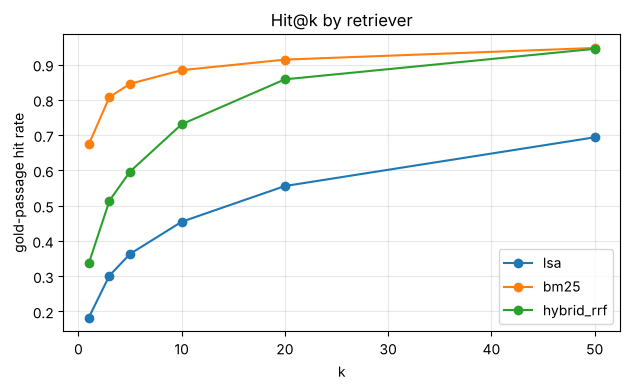

In [3]:
rows = []
for name in B.lists:
    for k in [1,3,5,10,20,50]:
        rows.append({"retriever": name, "k": k, "hit_rate": B.rel[name][:, :k].any(1).mean(), "answer_in_context": B.ans[name][:, :k].any(1).mean(),
                     "mean_rr@50": np.where(B.rank[name] <= 50, 1/B.rank[name], 0).mean() if k == 50 else np.nan})
rb = pd.DataFrame(rows); rb.to_csv(results_dir("csv")/"retrieval_baselines.csv", index=False)
display(rb.pivot(index="retriever", columns="k", values="hit_rate").round(3))
fig, ax = plt.subplots(figsize=(6.4, 4))
for name in B.lists:
    d = rb[rb.retriever == name]; ax.plot(d.k, d.hit_rate, "-o", label=name)
ax.set_xlabel("k"); ax.set_ylabel("gold-passage hit rate"); ax.set_title("Hit@k by retriever"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(results_dir("figures")/"recall_at_k.png", dpi=300); plt.show()

**Reading the result.** The distribution of the *rank of the first gold passage* is what an adaptive-k method must predict. If most queries have rank 1-3 but a long tail exists, a fixed k wastes tokens on easy queries or misses hard ones. Below: the empirical distribution that motivates the study.

rank<= 1     0.336
rank<= 2     0.447
rank<= 3     0.514
rank<= 5     0.597
rank<= 10    0.731
rank<= 20    0.858
rank<= 50    0.944
dtype: float64

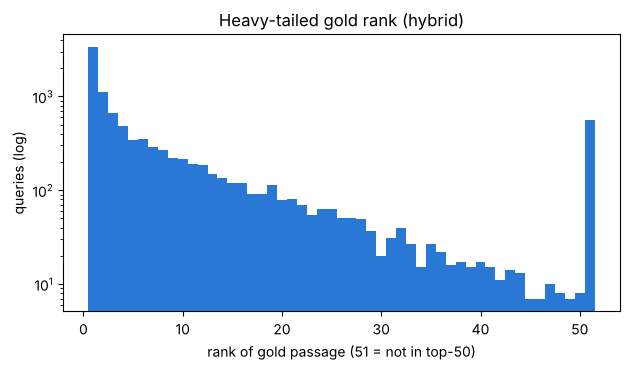

In [4]:
r = B.rank["hybrid_rrf"]
q = pd.Series({f"rank<= {k}": (r <= k).mean() for k in [1,2,3,5,10,20,50]}); q.to_csv(results_dir("csv")/"gold_rank_cdf_hybrid.csv"); display(q.round(3))
plt.figure(figsize=(6.4,3.8)); plt.hist(np.minimum(r, 51), bins=np.arange(1, 53)-.5, color="#2a78d6"); plt.yscale("log")
plt.xlabel("rank of gold passage (51 = not in top-50)"); plt.ylabel("queries (log)"); plt.title("Heavy-tailed gold rank (hybrid)")
plt.tight_layout(); plt.savefig(results_dir("figures")/"gold_rank_hist.png", dpi=300); plt.show()